# Task 5: Sales Prediction Using Python

## Introduction

Sales prediction is an important application of Machine Learning that helps businesses understand how advertising expenditure influences product sales.

The objective of this project is to build a regression model that predicts product sales based on advertising spending across three different media channels: TV, Radio, and Newspaper.

This project uses the Advertising dataset and applies Exploratory Data Analysis (EDA) to understand the relationships between advertising budgets and sales.

Two Machine Learning algorithms are implemented:
- Linear Regression
- Random Forest Regressor

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Finally, feature importance is analyzed to identify which advertising channel contributes most to the model's sales predictions.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the advertising dataset

df = pd.read_csv("advertising.csv")

# Display the first five rows
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [4]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information and data types
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [5]:
# Generate descriptive statistics

df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


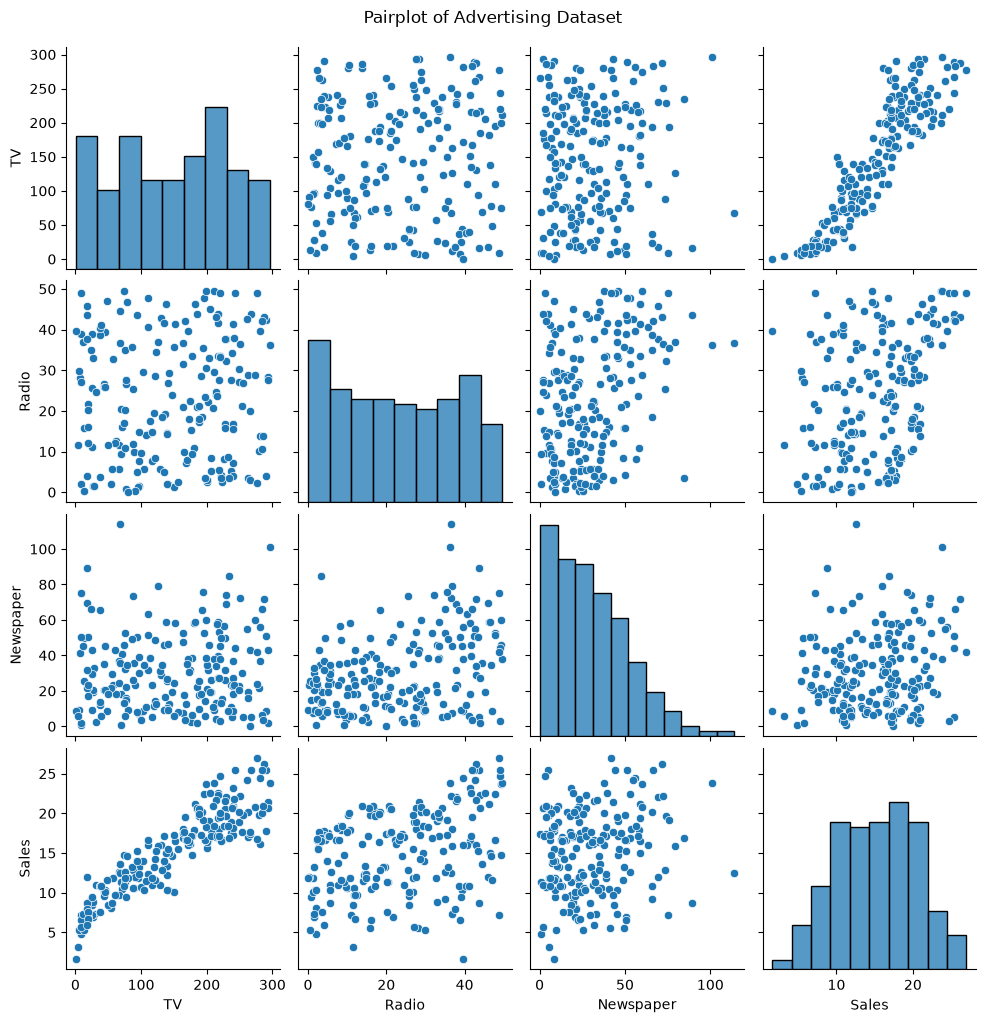

In [6]:
# Visualize relationships between all features

sns.pairplot(df)
plt.suptitle("Pairplot of Advertising Dataset", y=1.02)
plt.show()

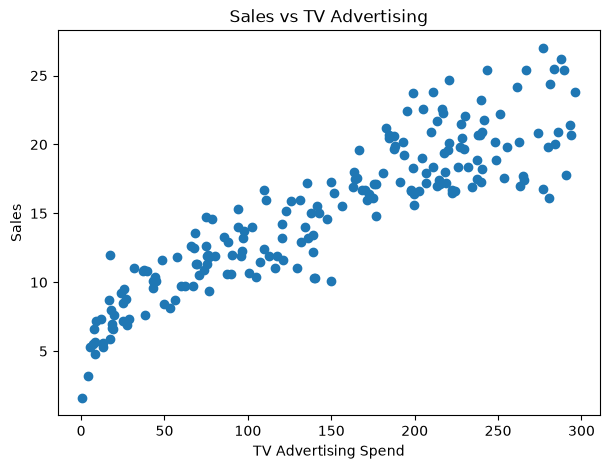

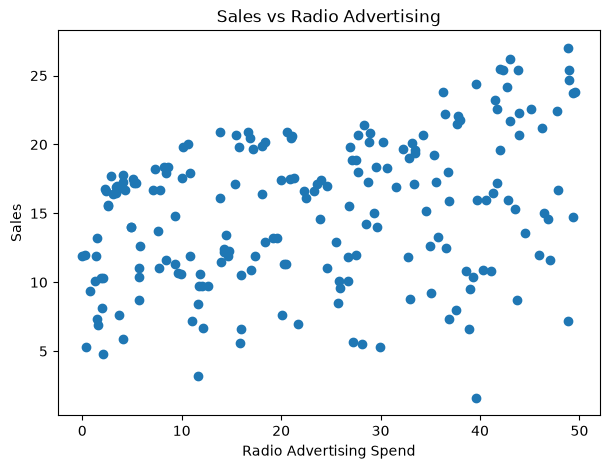

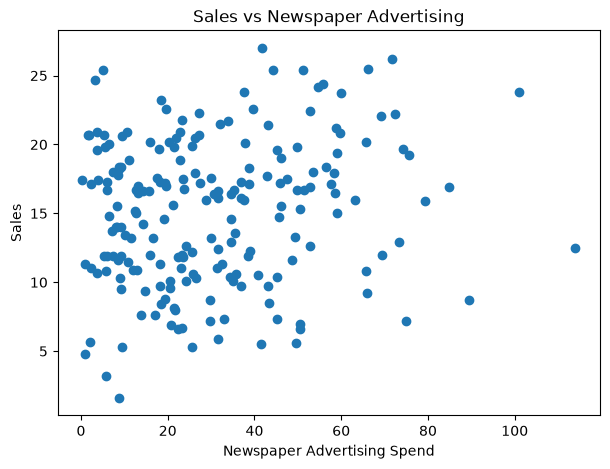

In [7]:
# Sales vs TV Advertising

plt.figure(figsize=(7, 5))
plt.scatter(df["TV"], df["Sales"])
plt.title("Sales vs TV Advertising")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")
plt.show()


# Sales vs Radio Advertising

plt.figure(figsize=(7, 5))
plt.scatter(df["Radio"], df["Sales"])
plt.title("Sales vs Radio Advertising")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.show()


# Sales vs Newspaper Advertising

plt.figure(figsize=(7, 5))
plt.scatter(df["Newspaper"], df["Sales"])
plt.title("Sales vs Newspaper Advertising")
plt.xlabel("Newspaper Advertising Spend")
plt.ylabel("Sales")
plt.show()

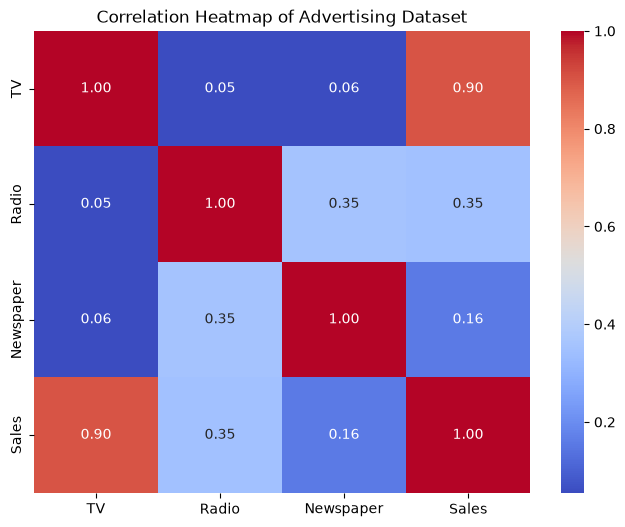

In [8]:
# Calculate correlation between all columns

correlation = df.corr()

# Create correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Advertising Dataset")
plt.show()

In [9]:
# Select input features
X = df[["TV", "Radio", "Newspaper"]]

# Select target variable
y = df["Sales"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (200, 3)
Target Variable Shape: (200,)


In [10]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (160, 3)
Testing Features: (40, 3)
Training Target: (160,)
Testing Target: (40,)


In [11]:
# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [12]:
# Create Random Forest Regressor model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
# Make predictions using Linear Regression
y_pred_lr = lr_model.predict(X_test)

# Make predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 5 Actual Sales:")
print(y_test.head().values)

print("\nFirst 5 Linear Regression Predictions:")
print(y_pred_lr[:5].round(2))

print("\nFirst 5 Random Forest Predictions:")
print(y_pred_rf[:5].round(2))

Predictions completed successfully!

First 5 Actual Sales:
[16.9 22.4 21.4  7.3 24.7]

First 5 Linear Regression Predictions:
[17.03 20.41 23.72  9.27 21.68]

First 5 Random Forest Predictions:
[17.3  22.48 19.77  6.78 22.96]


In [14]:
# Function to evaluate regression models

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("\n", model_name)
    print("-" * 40)
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


# Evaluate Linear Regression
evaluate_model(y_test, y_pred_lr, "Linear Regression")

# Evaluate Random Forest
evaluate_model(y_test, y_pred_rf, "Random Forest Regressor")


 Linear Regression
----------------------------------------
MAE : 1.2748
RMSE: 1.7052
R2 Score: 0.9059

 Random Forest Regressor
----------------------------------------
MAE : 0.918
RMSE: 1.1989
R2 Score: 0.9535


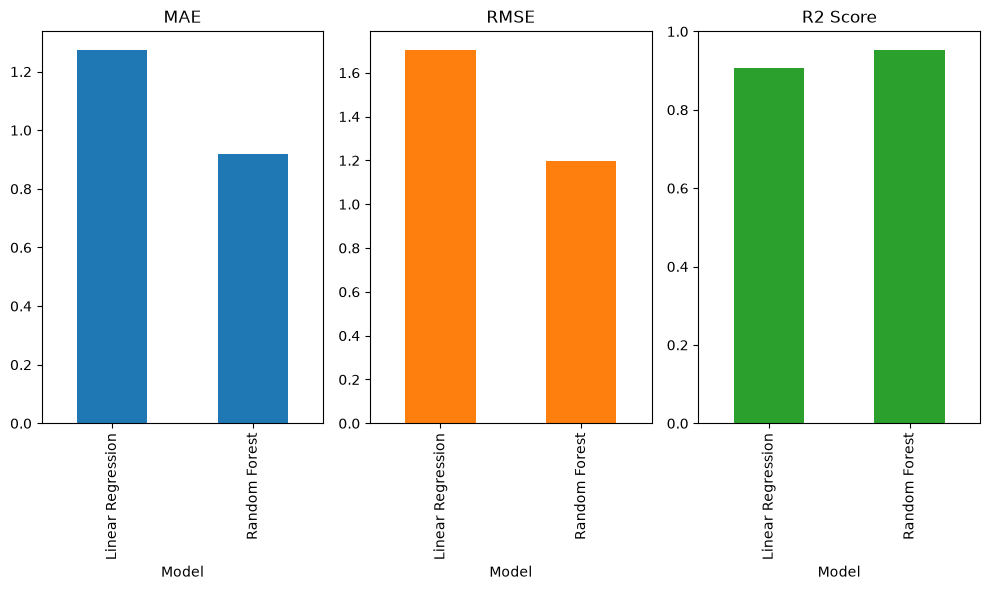

In [15]:
# Compare model performance

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ]
})

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    subplots=True,
    layout=(1, 3),
    legend=False
)

plt.tight_layout()
plt.show()

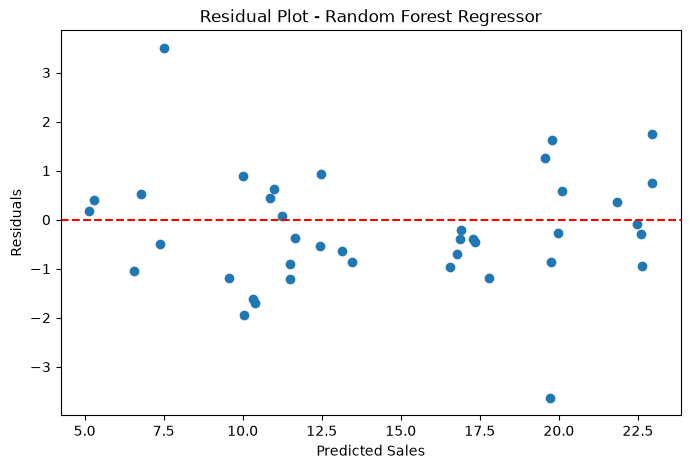

In [16]:
# Calculate residuals for Random Forest

residuals = y_test - y_pred_rf

# Create residual plot
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_rf, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - Random Forest Regressor")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.show()


Advertising Channel Importance:
  Advertising Channel  Importance
0                  TV    0.845355
1               Radio    0.136642
2           Newspaper    0.018003


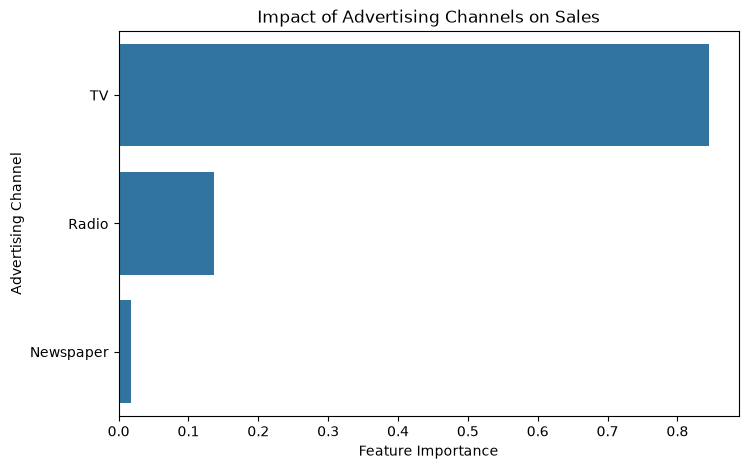

In [17]:
# Get feature importance from Random Forest

feature_importance = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Advertising Channel Importance:")
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Advertising Channel"
)

plt.title("Impact of Advertising Channels on Sales")
plt.xlabel("Feature Importance")
plt.ylabel("Advertising Channel")
plt.show()

In [18]:
# Create a sample advertising budget

sample_ad = pd.DataFrame([{
    "TV": 200,
    "Radio": 40,
    "Newspaper": 50
}])

# Predict sales using the best model
predicted_sales = rf_model.predict(sample_ad)

print("Sample Advertising Budget:")
print(sample_ad)

print("\nPredicted Sales:", round(predicted_sales[0], 2))

Sample Advertising Budget:
    TV  Radio  Newspaper
0  200     40         50

Predicted Sales: 21.01


## Observations

1. The dataset contains 200 records and 4 columns: TV, Radio, Newspaper, and Sales.
2. No missing values were found in the dataset.
3. Exploratory Data Analysis showed a strong positive relationship between TV advertising and Sales.
4. Two regression models were trained: Linear Regression and Random Forest Regressor.
5. Random Forest performed better than Linear Regression across all three evaluation metrics.
6. TV advertising had the highest feature importance (84.54%), followed by Radio (13.66%) and Newspaper (1.80%).
7. The Random Forest model predicted sales of 21.01 for the sample advertising budget.

## Model Evaluation Results

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| MAE | 1.2748 | 0.9180 |
| RMSE | 1.7052 | 1.1989 |
| R² Score | 0.9059 | 0.9535 |

## Conclusion

This project demonstrates how Machine Learning can be used to predict product sales based on advertising expenditure.

Among the two models, Random Forest Regressor achieved the best performance, with an R² score of 0.9535, an MAE of 0.9180, and an RMSE of 1.1989.

Feature importance analysis identified TV advertising as the most influential feature in the Random Forest model's predictions, followed by Radio and Newspaper.

Overall, this project provided practical experience in data analysis, visualization, regression modeling, model evaluation, and sales prediction using Python.